# 🔑 Solutions · Lesson 06: Machine-Learning Forecasting: Lag Features, Random Forest, Gradient Boosting & XGBoost

> Try every problem yourself first! Peek at hints before peeking here. Run the setup cell, then read each solution **and its explanation**: there is often more than one valid way.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

In [2]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

### ✅ Solution 6.1 · Build and inspect a supervised table

**Problem recap:** For **tomato**, build the 1-step-ahead ML table with `make_ml_table(tomato, h=1)`. (a) How many **complete rows** (no NaN in any feature or the target) does it have? Store it in `n_rows`.
  (b) List the feature names. (c) Which feature uses the *oldest* data, and why do the first rows have to be dropped?

In [3]:
tomato = load_weekly('tomato')
X, y = make_ml_table(tomato, h=1)
n_rows = int((X.notna().all(axis=1) & y.notna()).sum())
print(list(X.columns))
check('complete rows', n_rows, 573)

['ret_1w', 'ret_2w', 'ret_3w', 'ret_4w', 'ret_8w', 'ret_13w', 'ret_26w', 'ret_52w', 'dev_ma12', 'vol_13', 'rain6_l8', 'fuel_l8', 'fest', 'sin1', 'cos1', 'sin2', 'cos2', 'sin3', 'cos3']
✅ complete rows: correct!


**Why this works:** 626 weeks − 53 warm-up weeks (a 52-week return needs the price 52 weeks before the newest allowed observation, which is itself 1 week old) = 573 usable training rows. Warm-up rows must be **dropped, not filled**.

### ✅ Solution 6.2 · Trees can't extrapolate: prove it on rice

**Problem recap:** Rice trends upward strongly. Predict the 8-week-ahead price with a `RandomForestRegressor(200, random_state=0)` in two ways, using the **first 80 %** of rows for training and the **last 20 %** for testing:
  (A) **level target**: features from `make_features(rice, lags=(8, 9, 10, 12, 52), windows=(4, 12), h=8)`, target = price;
  (B) **return target**: `make_ml_table(rice, h=8)`, forecast = `price_{t-8} × exp(predicted return)`.
  Compare MAE and plot actual vs both predictions. Explain the result.

MAE (A) level target  : 8.91
MAE (B) return target : 5.52
max train price: 201.1 | max level-prediction: 198.1 | max actual in test: 205.7


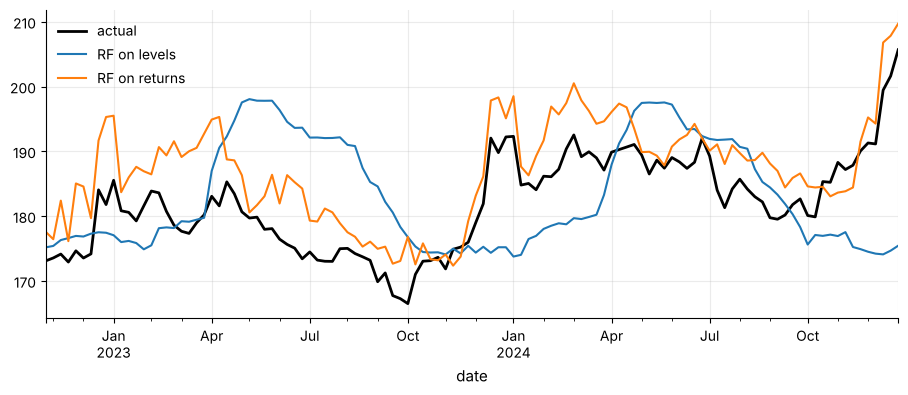

In [4]:
from sklearn.ensemble import RandomForestRegressor
rice = load_weekly('rice')
h = 8
# (A) level target
Xa, ya = make_features(rice, lags=(8, 9, 10, 12, 52), windows=(4, 12), h=h)
da = Xa.join(ya.rename('y')).dropna(); k = int(len(da) * 0.8)
rfA = RandomForestRegressor(200, random_state=0).fit(da.drop(columns='y').iloc[:k], da['y'].iloc[:k])
predA = pd.Series(rfA.predict(da.drop(columns='y').iloc[k:]), index=da.index[k:])
# (B) return target
Xb, yb = make_ml_table(rice, h=h)
db = Xb.join(yb.rename('y')).dropna(); kb = int(len(db) * 0.8)
rfB = RandomForestRegressor(200, random_state=0).fit(db.drop(columns='y').iloc[:kb], db['y'].iloc[:kb])
predB = rice['price'].shift(h).loc[db.index[kb:]] * np.exp(rfB.predict(db.drop(columns='y').iloc[kb:]))
actual = rice['price']
common = predA.index.intersection(predB.index)
print('MAE (A) level target  :', round(mae(actual.loc[common], predA.loc[common]), 2))
print('MAE (B) return target :', round(mae(actual.loc[common], predB.loc[common]), 2))
print('max train price:', round(da['y'].iloc[:k].max(), 1), '| max level-prediction:', round(predA.max(), 1), '| max actual in test:', round(actual.loc[common].max(), 1))
ax = actual.loc[common].plot(color='black', lw=2, label='actual'); predA.loc[common].plot(ax=ax, label='RF on levels'); predB.loc[common].plot(ax=ax, label='RF on returns'); ax.legend(); plt.show()

**Why this works:** A forest predicts by **averaging training targets**, so its output can never exceed the largest price it saw in training; when prices keep climbing it 'saturates' and plateaus. Re-expressing the target as a *return* keeps it inside a stable range that the test period also visits, and we rebuild the price by multiplying with the latest known price, so the trend is carried by the base price, not by the model.

### ✅ Solution 6.3 · Ridge vs naive on onion across horizons

**Problem recap:** Using `walk_forward_ml` with a `Ridge` pipeline (`StandardScaler` → `Ridge(alpha=10)`), evaluate **onion** at horizons `(1, 4, 8)` with `initial=470, step=8`.
  Compare against a *zero-return* model (the naive forecast) via MAE by horizon. At which horizons does the ML model beat naive, and by how much (skill = 1 − MAE_model/MAE_naive)?

In [5]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
onion = load_weekly('onion')
class ZeroReturn:
    def fit(self, X, y): return self
    def predict(self, X): return np.zeros(len(X))
res = {}
for name, fac in {'ridge': lambda: make_pipeline(StandardScaler(), Ridge(alpha=10)), 'naive': ZeroReturn}.items():
    wf = walk_forward_ml(onion, fac, horizons=(1, 4, 8), initial=470, step=8)
    res[name] = scores_by_horizon(wf)['MAE']
t = pd.DataFrame(res); t['skill'] = 1 - t['ridge'] / t['naive']
t.round(3)

,ridge,naive,skill
h,,,
1,3.218,2.823,-0.140
4,3.654,6.092,0.400
8,4.790,11.872,0.597


**Why this works:** Short-horizon price changes are dominated by unpredictable noise, so a model has little room to improve on naive at h = 1. At longer horizons the *predictable* components (the seasonal cycle and lagged drivers) account for a larger share of the movement, and the model's advantage grows.

### ✅ Solution 6.4 · Time-aware tuning of XGBoost

**Problem recap:** On **maize** (h = 4), tune `XGBRegressor` over `max_depth ∈ {2, 3, 4}` × `learning_rate ∈ {0.03, 0.1}` (use `n_estimators=200`, `subsample=0.8`) with
  `GridSearchCV` and `TimeSeriesSplit(n_splits=4, gap=3)` using `scoring='neg_mean_absolute_error'`, on the training rows *before* the final 52 weeks.
  Then evaluate the best and a default `XGBRegressor(random_state=0)` on the final 52-week hold-out (MAE of the **price** forecast).

In [6]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
mz = load_weekly('maize')
h = 4
X, y = make_ml_table(mz, h=h)
d = X.join(y.rename('y')).dropna()
tr, te = d.iloc[:-52], d.iloc[-52:]
grid = GridSearchCV(XGBRegressor(n_estimators=200, subsample=0.8, random_state=0, n_jobs=1),
                    {'max_depth': [2, 3, 4], 'learning_rate': [0.03, 0.1]},
                    cv=TimeSeriesSplit(n_splits=4, gap=h - 1), scoring='neg_mean_absolute_error')
grid.fit(tr.drop(columns='y'), tr['y'])
print('best params:', grid.best_params_)
base_price = mz['price'].shift(h).loc[te.index]
for name, model in {'tuned': grid.best_estimator_, 'default': XGBRegressor(random_state=0, n_jobs=1).fit(tr.drop(columns='y'), tr['y'])}.items():
    pred = base_price * np.exp(model.predict(te.drop(columns='y')))
    print(f'{name:<8} hold-out MAE: {mae(mz["price"].loc[te.index], pred):.2f}')
print('naive    hold-out MAE:', round(mae(mz['price'].loc[te.index], base_price), 2))

best params: {'learning_rate': 0.03, 'max_depth': 2}
tuned    hold-out MAE: 5.60
default  hold-out MAE: 5.62
naive    hold-out MAE: 8.63


**Why this works:** `TimeSeriesSplit` always validates on data that comes *after* the training fold. The `gap` removes the overlap between a training row's target window and the validation period. Tuning on shuffled K-fold would have picked hyper-parameters that exploit the leak. Notice that the tuned and the default model score almost identically on the hold-out: tuning a small grid rarely rescues or ruins a model: **feature quality and the target transformation matter far more than hyper-parameters**. The hold-out is your honest referee either way.

### ✅ Solution 6.5 · Recursive vs direct for an 8-step forecast

**Problem recap:** On **maize** use only the **last 4 weekly log returns** as features. Train on the first 470 weeks, then evaluate at *every* origin in the remaining weeks (no refitting):
  (A) **Direct**: a `Ridge(alpha=1)` mapping the 4 returns at the origin to the 8-week log return.
  (B) **Recursive**: a `Ridge(alpha=1)` mapping 4 returns to the *next-week* return; apply it 8 times, feeding each prediction back in.
  Report the MAE of the 8-week-ahead price forecast for both and for naive.

In [7]:
from sklearn.linear_model import Ridge
mz = load_weekly('maize')
lp = np.log(mz['price']); r = lp.diff()
F = np.column_stack([r.shift(k) for k in range(4)])           # [r_t, r_{t-1}, r_{t-2}, r_{t-3}]
target_direct = (lp.shift(-8) - lp).values
target_next = r.shift(-1).values
n_train = 470
valid = ~np.isnan(F).any(axis=1)
train_idx = np.where(valid & ~np.isnan(target_direct))[0]; train_idx = train_idx[train_idx + 8 < n_train]    # targets fully inside the training window
direct = Ridge(alpha=1).fit(F[train_idx], target_direct[train_idx])
rec_idx = np.where(valid & ~np.isnan(target_next))[0]; rec_idx = rec_idx[rec_idx + 1 < n_train]
recursive = Ridge(alpha=1).fit(F[rec_idx], target_next[rec_idx])
res = {'naive': [], 'direct': [], 'recursive': []}; actual = []
for t in range(n_train, len(mz) - 8):
    x = F[t]
    actual.append(mz['price'].iloc[t + 8]); p0 = mz['price'].iloc[t]
    res['naive'].append(p0)
    res['direct'].append(p0 * np.exp(direct.predict([x])[0]))
    window = list(x); total = 0.0
    for _ in range(8):
        step = recursive.predict([window])[0]; total += step; window = [step] + window[:3]
    res['recursive'].append(p0 * np.exp(total))
for name, f in res.items():
    print(f'{name:<10} MAE at h=8: {mae(actual, f):.2f}')

naive      MAE at h=8: 14.22
direct     MAE at h=8: 14.05
recursive  MAE at h=8: 14.24


**Why this works:** The recursive strategy re-uses one 1-step model, but its prediction errors are fed back as inputs, so they can compound (and the model is trained to be good at h = 1, not h = 8). The direct strategy trains a separate model *for the horizon you care about*, at the cost of fitting several models. With weakly predictable noisy returns, both land close to naive here; the point is the *mechanics*, which matter more once you add rich features.